In [1]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import re
import os
import time
from datetime import datetime
from pathlib import Path
from email.message import EmailMessage
import smtplib

In [2]:
PRODUCT_URL = (
    "https://www.amazon.com/dp/B01B77W0JI"
)

CSV_FILE = Path("amazon_price_history.csv")
DEBUG_HTML_FILE = Path("amazon_debug.html")


# Change this to the price you care about
TARGET_PRICE = 15.00

In [3]:
HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
        "AppleWebKit/537.36 (KHTML, like Gecko) "
        "Chrome/153.0.0.0 Safari/537.36"
    ),
    "Accept": (
        "text/html,application/xhtml+xml,"
        "application/xml;q=0.9,image/avif,image/webp,*/*;q=0.8"
    ),
    "Accept-Language": "en-US,en;q=0.9",
    "DNT": "1",
    "Connection": "keep-alive",
    "Upgrade-Insecure-Requests": "1"
}

In [4]:
session = requests.Session()
session.headers.update(HEADERS)

In [5]:
def download_page(url):
    """
    Download an Amazon product page.

    Also prints debugging information and saves
    the returned HTML to a local file.
    """

    try:

        print("\nDownloading Amazon page...")

        response = session.get(
            url,
            timeout=20,
            allow_redirects=True
        )

        response.raise_for_status()

        print("Page downloaded successfully.")
        print("Status code:", response.status_code)

        # Show the final URL after redirects
        print("Final URL:", response.url)

        # Show how much HTML Amazon returned
        print("HTML length:", len(response.text))

        # Create BeautifulSoup temporarily
        debug_soup = BeautifulSoup(
            response.text,
            "html.parser"
        )

        # Display page title
        if debug_soup.title:

            print(
                "Page title:",
                debug_soup.title.get_text(
                    " ",
                    strip=True
                )
            )

        else:

            print("Page title: Not found")

        # Save raw HTML for debugging
        with open(
            DEBUG_HTML_FILE,
            "w",
            encoding="utf-8"
        ) as file:

            file.write(response.text)

        print(
            "Debug HTML saved to:",
            DEBUG_HTML_FILE.resolve()
        )

        return response.text

    except requests.exceptions.RequestException as error:

        print("\nCould not download the page.")

        print("Error:", error)

        return None




In [6]:
def create_soup(html):
    """
    Convert HTML into a BeautifulSoup object.
    """

    if html is None:
        return None

    return BeautifulSoup(html, "html.parser")

In [7]:
def find_text(soup, selectors):
    """
    Try several CSS selectors until one works.
    """

    if soup is None:
        return None

    for selector in selectors:

        element = soup.select_one(selector)

        if element:

            text = element.get_text(
                " ",
                strip=True
            )

            if text:
                return text

    return None


In [8]:
def get_title(soup):

    selectors = [

        "#productTitle",

        "span#productTitle",

        "h1#title",

        "h1.a-size-large",

        "h1"
    ]

    title = find_text(
        soup,
        selectors
    )

    if title:

        return title

    # Fallback: use HTML <title>
    if soup and soup.title:

        page_title = soup.title.get_text(
            " ",
            strip=True
        )

        if page_title:

            return page_title

    return "Title not found"


In [9]:
def get_price(soup):

    if soup is None:

        return None



    selectors = [

        "span.a-price span.a-offscreen",

        "#priceblock_ourprice",

        "#priceblock_dealprice",

        "#priceblock_saleprice",

        "span[data-a-color='price'] span.a-offscreen",

        "span.a-price"
    ]

    price_text = find_text(
        soup,
        selectors
    )

    if price_text:

        price = parse_price(
            price_text
        )

        if price is not None:

            return price

   

    whole = find_text(
        soup,
        [
            "span.a-price-whole"
        ]
    )

    fraction = find_text(
        soup,
        [
            "span.a-price-fraction"
        ]
    )

    if whole:

        whole_clean = re.sub(
            r"[^0-9]",
            "",
            whole
        )

        fraction_clean = re.sub(
            r"[^0-9]",
            "",
            fraction or "00"
        )

        if whole_clean:

            try:

                return float(
                    whole_clean
                    + "."
                    + fraction_clean[:2].ljust(2, "0")
                )

            except ValueError:

                pass

    return None




In [10]:
def parse_price(price_text):
    """
    Convert Amazon price text into a float.

    Examples:

        "$19.99" -> 19.99
        "$1,299.99" -> 1299.99
        "19.99" -> 19.99
    """

    if not price_text:

        return None

    # Remove currency symbols and letters
    cleaned = re.sub(
        r"[^0-9.,]",
        "",
        price_text
    )

    if not cleaned:

        return None

    try:

        # US Amazon normally uses:
        # 1,299.99

        if "," in cleaned and "." in cleaned:

            cleaned = cleaned.replace(
                ",",
                ""
            )

        # Example:
        # 19,99
        elif "," in cleaned and "." not in cleaned:

            parts = cleaned.split(",")

            if (
                len(parts) == 2
                and len(parts[1]) <= 2
            ):

                cleaned = (
                    parts[0]
                    + "."
                    + parts[1]
                )

            else:

                cleaned = cleaned.replace(
                    ",",
                    ""
                )

        return float(cleaned)

    except ValueError:

        return None


In [11]:
def get_rating(soup):

    selectors = [
        "span.a-icon-alt",
        "i.a-icon-star span"
    ]

    rating_text = find_text(
        soup,
        selectors
    )

    if not rating_text:
        return None

    match = re.search(
        r"([0-5](?:\.[0-9])?)",
        rating_text
    )

    if match:
        return float(match.group(1))

    return None


In [12]:
def get_review_count(soup):

    selectors = [
        "#acrCustomerReviewText",
        "span[data-hook='total-review-count']"
    ]

    review_text = find_text(
        soup,
        selectors
    )

    if not review_text:
        return None

    numbers = re.sub(
        r"[^0-9]",
        "",
        review_text
    )

    if numbers:
        return int(numbers)

    return None




In [13]:
def get_availability(soup):

    selectors = [
        "#availability span",
        "#availability",
        "#outOfStock"
    ]

    availability = find_text(
        soup,
        selectors
    )

    if availability:
        return availability

    return "Availability information not found"



In [14]:
def check_amazon_response(html):

    """
    Check whether Amazon returned a normal page
    or a bot-check / unusual page.
    """

    if html is None:

        return False

    html_lower = html.lower()

    blocked_words = [

        "enter the characters you see below",

        "sorry, we just need to make sure you're not a robot",

        "robot check",

        "captcha",

        "validatecaptcha",

        "type the characters you see",

        "automated access",

        "sorry, something went wrong"
    ]

    for word in blocked_words:

        if word in html_lower:

            print(
                "\nAmazon appears to have returned "
                "a bot-check or unusual page."
            )

            print(
                "Detected:",
                word
            )

            return False

    return True



In [15]:
def scrape_product(url):

    print("\nStarting Amazon scraper...")

    print("-" * 60)

    html = download_page(
        url
    )

    if html is None:

        return None

    # Check Amazon response
    if not check_amazon_response(html):

        return None

    soup = create_soup(
        html
    )

    if soup is None:

        return None

    product = {

        "Title": get_title(
            soup
        ),

        "Price": get_price(
            soup
        ),

        "Rating": get_rating(
            soup
        ),

        "Reviews": get_review_count(
            soup
        ),

        "Availability": get_availability(
            soup
        ),

        "Collected_At": datetime.now().strftime(
            "%Y-%m-%d %H:%M:%S"
        ),

        "Product_URL": url
    }

    return product




In [16]:
def save_product(data):

    if data is None:
        print("Nothing to save.")
        return

    new_row = pd.DataFrame([data])

    if CSV_FILE.exists():

        old_data = pd.read_csv(
            CSV_FILE
        )

        combined = pd.concat(
            [old_data, new_row],
            ignore_index=True
        )

    else:

        combined = new_row

    combined.to_csv(
        CSV_FILE,
        index=False
    )

    print("\nData saved successfully.")
    print("File:", CSV_FILE.resolve())



In [17]:
def display_product(data):

    if data is None:
        return

    print("\n")
    print("=" * 60)
    print("AMAZON PRODUCT INFORMATION")
    print("=" * 60)

    print("Title:")
    print(data["Title"])

    print("\nPrice:")
    print(data["Price"])

    print("\nRating:")
    print(data["Rating"])

    print("\nReviews:")
    print(data["Reviews"])

    print("\nAvailability:")
    print(data["Availability"])

    print("\nCollected:")
    print(data["Collected_At"])

    print("=" * 60)



In [18]:
def check_target_price(data, target_price):

    if data is None:
        return False

    current_price = data["Price"]

    if current_price is None:

        print(
            "\nPrice could not be detected."
        )

        return False

    print(
        f"\nCurrent price: ${current_price:.2f}"
    )

    print(
        f"Target price: ${target_price:.2f}"
    )

    if current_price <= target_price:

        print(
            "\nPRICE ALERT!"
        )

        print(
            "The product is at or below your target price."
        )

        return True

    else:

        difference = current_price - target_price

        print(
            f"\nStill ${difference:.2f} above your target."
        )

        return False



In [19]:
def load_history():

    if not CSV_FILE.exists():

        print(
            "\nNo price history exists yet."
        )

        return pd.DataFrame()

    history = pd.read_csv(
        CSV_FILE
    )

    history["Price"] = pd.to_numeric(
        history["Price"],
        errors="coerce"
    )

    history["Collected_At"] = pd.to_datetime(
        history["Collected_At"],
        errors="coerce"
    )

    return history


In [20]:
def analyze_history():

    history = load_history()

    if history.empty:

        return

    prices = history["Price"].dropna()

    if prices.empty:

        print(
            "No valid prices available for analysis."
        )

        return

    print("\n")
    print("=" * 60)
    print("PRICE HISTORY ANALYSIS")
    print("=" * 60)

    print(
        f"Number of observations: {len(prices)}"
    )

    print(
        f"Highest price: ${prices.max():.2f}"
    )

    print(
        f"Lowest price: ${prices.min():.2f}"
    )

    print(
        f"Average price: ${prices.mean():.2f}"
    )

    print(
        f"Latest price: ${prices.iloc[-1]:.2f}"
    )

    if len(prices) >= 2:

        previous = prices.iloc[-2]
        current = prices.iloc[-1]

        change = current - previous

        percentage = (
            change / previous
        ) * 100

        print(
            f"Price change: ${change:.2f}"
        )

        print(
            f"Percentage change: {percentage:.2f}%"
        )

    print("=" * 60)



In [21]:
def show_history():

    history = load_history()

    if history.empty:
        return

    print("\nComplete price history:")

    display(history)

In [22]:
def send_email_alert(
    product,
    sender_email,
    receiver_email,
    app_password
):

    if product is None:
        return

    price = product["Price"]

    if price is None:
        return

    subject = (
        f"Amazon Price Alert: ${price:.2f}"
    )

    body = f"""
Amazon Price Alert

Product:
{product["Title"]}

Current price:
${price:.2f}

Target price:
${TARGET_PRICE:.2f}

Rating:
{product["Rating"]}

Availability:
{product["Availability"]}

Product:
{product["Product_URL"]}

Checked:
{product["Collected_At"]}
"""

    message = EmailMessage()

    message["Subject"] = subject
    message["From"] = sender_email
    message["To"] = receiver_email

    message.set_content(body)

    try:

        with smtplib.SMTP_SSL(
            "smtp.gmail.com",
            465
        ) as server:

            server.login(
                sender_email,
                app_password
            )

            server.send_message(
                message
            )

        print(
            "\nEmail alert sent successfully."
        )

    except Exception as error:

        print(
            "\nEmail could not be sent."
        )

        print(
            "Error:",
            error
        )


In [23]:
def run_scraper():

    print("\n")
    print("AMAZON WEB SCRAPER")
    print("=" * 60)

    product = scrape_product(
        PRODUCT_URL
    )

    if product is None:

        print(
            "\nScraping failed."
        )

        return None

    display_product(
        product
    )

    save_product(
        product
    )

    check_target_price(
        product,
        TARGET_PRICE
    )

    analyze_history()

    return product


In [24]:
product_data = run_scraper()



AMAZON WEB SCRAPER

Starting Amazon scraper...
------------------------------------------------------------

Page downloaded successfully.
Status code: 200
Final URL: https://www.amazon.com/dp/B01B77W0JI
HTML length: 2374537
Page title: Hanes Women's EcoSmart Full-Zip Hoodie Sweatshirt, Pale Pink, Small at Amazon Women’s Clothing store
Debug HTML saved to: C:\Users\sozma\amazon_debug.html


AMAZON PRODUCT INFORMATION
Title:
Hanes Women's EcoSmart Fleece Sweatshirt for Women, Soft Midweight - Full-Zip Hoodie, Sweatshirt, or 1/4 Zip

Price:
1590.0

Rating:
4.4

Reviews:
46720

Availability:
This item cannot be shipped to your selected delivery location. Please choose a different delivery location.

Collected:
2026-10-09 22:09:27

Data saved successfully.
File: C:\Users\sozma\amazon_price_history.csv

Current price: $1590.00
Target price: $15.00

Still $1575.00 above your target.


PRICE HISTORY ANALYSIS
Number of observations: 9
Highest price: $2020.00
Lowest price: $1590.00
Average pr

In [25]:
print("\n")
print("SAVED DATA")
print("=" * 60)

history_df = load_history()

if not history_df.empty:

    display(
        history_df
    )




SAVED DATA


,Title,Price,Rating,Reviews,Availability,Collected_At,Product_URL
0,Title not found,NaN,NaN,NaN,Availability information not found,2026-10-05 23:50:37,https://www.amazon.com/dp/B01B77W0JI
1,Hanes Women's EcoSmart Full-Zip Hoodie Sweatsh...,NaN,NaN,NaN,Availability information not found,2026-10-06 00:05:40,https://www.amazon.com/dp/B01B77W0JI
2,Hanes Women's EcoSmart Fleece Sweatshirt for W...,2020.0,4.4,46705.0,This item cannot be shipped to your selected d...,2026-10-06 00:07:36,https://www.amazon.com/dp/B01B77W0JI
3,Hanes Women's EcoSmart Fleece Sweatshirt for W...,2020.0,4.4,46705.0,This item cannot be shipped to your selected d...,2026-10-06 00:09:08,https://www.amazon.com/dp/B01B77W0JI
4,Hanes Women's EcoSmart Full-Zip Hoodie Sweatsh...,NaN,NaN,NaN,Availability information not found,2026-10-06 00:15:01,https://www.amazon.com/dp/B01B77W0JI
5,Hanes Women's EcoSmart Fleece Sweatshirt for W...,2020.0,4.4,46705.0,This item cannot be shipped to your selected d...,2026-10-06 00:15:15,https://www.amazon.com/dp/B01B77W0JI
6,Hanes Women's EcoSmart Fleece Sweatshirt for W...,2020.0,4.4,46705.0,This item cannot be shipped to your selected d...,2026-10-06 00:15:21,https://www.amazon.com/dp/B01B77W0JI
7,Hanes Women's EcoSmart Fleece Sweatshirt for W...,1590.0,4.4,46720.0,This item cannot be shipped to your selected d...,2026-10-09 21:56:16,https://www.amazon.com/dp/B01B77W0JI
8,Hanes Women's EcoSmart Fleece Sweatshirt for W...,1590.0,4.4,46720.0,This item cannot be shipped to your selected d...,2026-10-09 22:01:39,https://www.amazon.com/dp/B01B77W0JI
9,Hanes Women's EcoSmart Fleece Sweatshirt for W...,1590.0,4.4,46720.0,This item cannot be shipped to your selected d...,2026-10-09 22:01:44,https://www.amazon.com/dp/B01B77W0JI


In [26]:
if not history_df.empty:

    print("\nPRICE STATISTICS")
    print("=" * 60)

    print(
        history_df["Price"].describe()
    )



PRICE STATISTICS
count       9.000000
mean     1781.111111
std       226.629899
min      1590.000000
25%      1590.000000
50%      1590.000000
75%      2020.000000
max      2020.000000
Name: Price, dtype: float64


In [27]:
def monitor_price(
    interval_hours=24,
    target_price=TARGET_PRICE
):

    print(
        f"Price monitor started."
    )

    print(
        f"Checking every {interval_hours} hours."
    )

    print(
        "Stop the Jupyter cell manually when needed."
    )

    while True:

        product = run_scraper()

        if product is not None:

            price = product["Price"]

            if (
                price is not None
                and price <= target_price
            ):

                print(
                    "\nTARGET PRICE REACHED!"
                )

        wait_seconds = (
            interval_hours * 60 * 60
        )

        print(
            f"\nNext check in "
            f"{interval_hours} hour(s)."
        )

        time.sleep(
            wait_seconds
        )



In [28]:
if not history_df.empty:

    print("\nPRICE STATISTICS")
    print("=" * 60)

    print(
        history_df["Price"].describe()
    )



PRICE STATISTICS
count       9.000000
mean     1781.111111
std       226.629899
min      1590.000000
25%      1590.000000
50%      1590.000000
75%      2020.000000
max      2020.000000
Name: Price, dtype: float64


In [29]:
#send_email_alert(
 #   product=product_data,
  #  sender_email="sozmahmoud68@gmail.com",
   # receiver_email="sozmahmoud68@gmail.com",
    #app_password=" "
#)

In [30]:
product_data = run_scraper()



AMAZON WEB SCRAPER

Starting Amazon scraper...
------------------------------------------------------------

Page downloaded successfully.
Status code: 200
Final URL: https://www.amazon.com/dp/B01B77W0JI
HTML length: 2374423
Page title: Hanes Women's EcoSmart Full-Zip Hoodie Sweatshirt, Pale Pink, Small at Amazon Women’s Clothing store
Debug HTML saved to: C:\Users\sozma\amazon_debug.html


AMAZON PRODUCT INFORMATION
Title:
Hanes Women's EcoSmart Fleece Sweatshirt for Women, Soft Midweight - Full-Zip Hoodie, Sweatshirt, or 1/4 Zip

Price:
1590.0

Rating:
4.4

Reviews:
46720

Availability:
This item cannot be shipped to your selected delivery location. Please choose a different delivery location.

Collected:
2026-10-09 22:09:39

Data saved successfully.
File: C:\Users\sozma\amazon_price_history.csv

Current price: $1590.00
Target price: $15.00

Still $1575.00 above your target.


PRICE HISTORY ANALYSIS
Number of observations: 10
Highest price: $2020.00
Lowest price: $1590.00
Average p

In [ ]:
monitor_price(interval_hours=24)

Price monitor started.
Checking every 24 hours.
Stop the Jupyter cell manually when needed.


AMAZON WEB SCRAPER

Starting Amazon scraper...
------------------------------------------------------------

Page downloaded successfully.
Status code: 200
Final URL: https://www.amazon.com/dp/B01B77W0JI
HTML length: 2261071
Page title: Hanes Women's EcoSmart Full-Zip Hoodie Sweatshirt, Pale Pink, Small at Amazon Women’s Clothing store
Debug HTML saved to: C:\Users\sozma\amazon_debug.html


AMAZON PRODUCT INFORMATION
Title:
Hanes Women's EcoSmart Fleece Sweatshirt for Women, Soft Midweight - Full-Zip Hoodie, Sweatshirt, or 1/4 Zip

Price:
1590.0

Rating:
4.4

Reviews:
46720

Availability:
This item cannot be shipped to your selected delivery location. Please choose a different delivery location.

Collected:
2026-10-09 22:09:43

Data saved successfully.
File: C:\Users\sozma\amazon_price_history.csv

Current price: $1590.00
Target price: $15.00

Still $1575.00 above your target.


PRICE HISTORY 

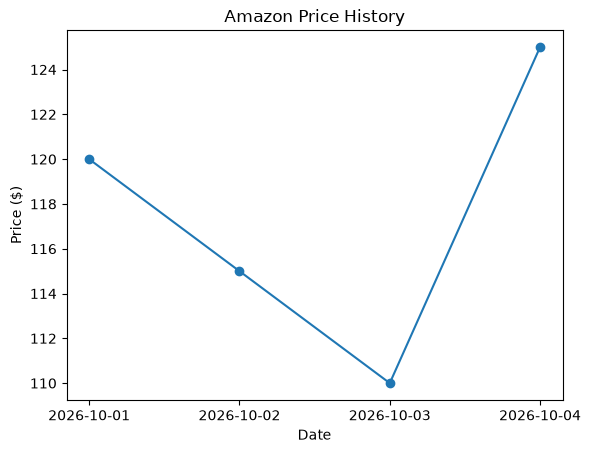

In [1]:

import pandas as pd
import matplotlib.pyplot as plt

data = {
    "Date": ["2026-10-01", "2026-10-02", "2026-10-03", "2026-10-04"],
    "Price": [120, 115, 110, 125]
}

df = pd.DataFrame(data)

plt.plot(df["Date"], df["Price"], marker="o")

plt.title("Amazon Price History")
plt.xlabel("Date")
plt.ylabel("Price ($)")

plt.show()

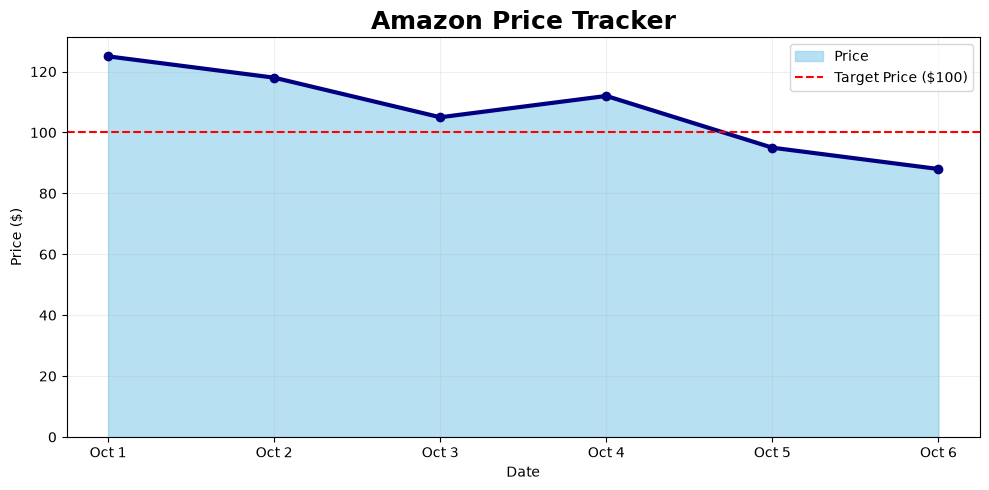

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame({
    "Date": ["Oct 1", "Oct 2", "Oct 3", "Oct 4", "Oct 5", "Oct 6"],
    "Price": [125, 118, 105, 112, 95, 88]
})

df.plot(
    x="Date",
    y="Price",
    kind="area",
    figsize=(10, 5),
    color="skyblue",
    alpha=0.6,
    legend=False
)

plt.plot(df["Date"], df["Price"], color="navy", marker="o", linewidth=3)

plt.axhline(y=100, color="red", linestyle="--", label="Target Price ($100)")

plt.title("Amazon Price Tracker", fontsize=18, fontweight="bold")
plt.xlabel("Date")
plt.ylabel("Price ($)")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()